# Lab 4, Notebook A — Filtering the spectrum

*Linear Algebra for Data Science, UCU 2026. Uses Session 5.2 (SVD, Eckart–Young, truncated SVD, filter factors) and, for A3, the convolution theorem for the discrete Fourier transform.*

An image is a matrix, and the SVD sorts it into rank-one layers by importance. In this notebook you will keep, drop or shrink those layers for three different purposes: to **compress** an image (A1), to remove **noise** from it (A2), and to undo a **blur** (A3). The same idea runs through all three: write the problem in a basis where it is diagonal, then decide what to do with each coordinate. The last part also shows why a mathematically exact inverse can be numerically worthless.

**How to work.** Most tasks ask you to **predict first, in writing, then compute, then explain any difference**. Write the prediction *before* running the cell. A wrong prediction with an honest explanation earns more at the defence than a correct number you cannot explain.

**Rules.**
- Do not call `np.linalg.inv` or `np.linalg.pinv` anywhere.
- Never form the blur matrix of the full image (you will see in A3 why you cannot). The only explicit circulant matrix allowed is the small 1-D one in A3(a).
- You may use `np.linalg.svd`, `np.linalg.norm`, `scipy.linalg.qr` and `np.fft`. Library shortcuts such as `scipy.linalg.circulant` are allowed only where a cell says **check**.
- Do not change the seeds.
- Before you submit, run `Kernel → Restart & Run All`.

**Marking.** Core A is worth 2 points at the defence; the code point and the extension are shared with Notebook B.

**Contents.** A1 Compression and Eckart–Young · A2 Denoising · A3 Deblurring · Extension E1 (choosing λ without knowing the noise). Attempt **at most one** extension in the whole lab.

| | |
|---|---|
| **Team member 1** | *Oleksandr, Korniienko* |
| **Team member 2** | *Liubomyr, Smerek* |
| **Extension attempted** (at most one in the whole lab) | *none* |
| **Late days used on this lab** | *0* |
| **Runs top to bottom from a clean kernel** | *yes* |

python 3.11.9 | numpy 2.4.6 | scipy 1.17.1 | matplotlib 3.11.2 | sklearn 1.9.1
image: 427 x 640 = 273280 pixels


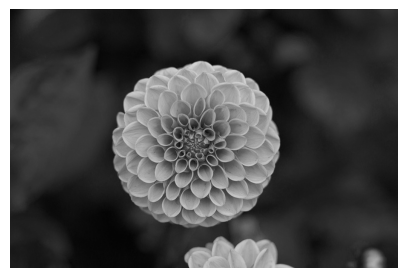

In [1]:
import sys, time
import numpy as np
import scipy, scipy.linalg as sl
import matplotlib, matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_sample_image

print("python", sys.version.split()[0], "| numpy", np.__version__, "| scipy", scipy.__version__,
      "| matplotlib", matplotlib.__version__, "| sklearn", sklearn.__version__)
np.set_printoptions(precision=4, suppress=False, linewidth=110)

img = load_sample_image("flower.jpg").astype(float).mean(axis=2) / 255   # grey levels in [0, 1]
m, n = img.shape
rel = lambda X: np.linalg.norm(X - img) / np.linalg.norm(img)            # relative Frobenius error
print(f"image: {m} x {n} = {m*n} pixels")
plt.figure(figsize=(5, 3.4)); plt.imshow(img, cmap="gray", vmin=0, vmax=1); plt.axis("off"); plt.show()

---
## A1. Compression and Eckart–Young

Write the SVD as $A = \sum_j \sigma_j \mathbf{u}_j\mathbf{v}_j^\top$. The truncated SVD $A_k = \sum_{j\le k}\sigma_j\mathbf{u}_j\mathbf{v}_j^\top$ is stored as $k$ columns of $U$, $k$ rows of $V^\top$ and $k$ singular values.

**(a)** Implement `rank_k(U, s, Vt, k)`, which returns $A_k$ from the thin SVD. Use broadcasting, not `np.diag`, and do not multiply by any zero columns.

In [2]:
U, s, Vt = np.linalg.svd(img, full_matrices=False)

def rank_k(U, s, Vt, k):
    return (U[:, :k] * s[:k]) @ Vt[:k]

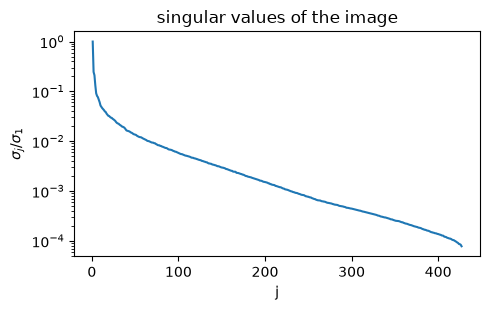

sigma_1 = 149.2, sigma_427 = 1.16e-02


In [3]:
# check
assert np.allclose(rank_k(U, s, Vt, len(s)), img)
assert np.linalg.matrix_rank(rank_k(U, s, Vt, 7)) == 7
plt.figure(figsize=(5, 3.2))
plt.semilogy(np.arange(1, len(s) + 1), s / s[0])
plt.xlabel("j"); plt.ylabel(r"$\sigma_j/\sigma_1$"); plt.title("singular values of the image"); plt.tight_layout(); plt.show()
print(f"sigma_1 = {s[0]:.1f}, sigma_{len(s)} = {s[-1]:.2e}")

**(b)** *Predict, then compute.* Implement two functions that use **only the singular values**:
- `predicted_errors(s, k)` returns the relative Frobenius error $\|A-A_k\|_F/\|A\|_F$ and the 2-norm error $\|A-A_k\|_2$ of the best rank-$k$ approximation;
- `storage(k, m, n)` returns the fraction of the $mn$ pixel values needed to store $A_k$ in factored form.

Before running the comparison below: will the actual errors of `rank_k` **equal** your predictions, or only be bounded by them? Name the theorem.

**Your prediction** *(write it before running the next cell)*: They will be exactly equal, not just bounded, because by the Eckart–Young theorem the truncated SVD is the best rank-$k$ approximation and its error is $\sqrt{\sum_{j>k}\sigma_j^2}$ in Frobenius norm and $\sigma_{k+1}$ in the 2-norm.

In [4]:
def predicted_errors(s, k):
    rel_f = np.sqrt(np.sum(s[k:] ** 2) / np.sum(s ** 2))
    two = s[k] if k < len(s) else 0.0
    return rel_f, two

def storage(k, m, n):
    return k * (m + n + 1) / (m * n)

In [5]:
# check
print("   k | predicted rel. F  actual rel. F | predicted 2-norm  actual 2-norm | storage")
for k in [5, 10, 20, 50, 100]:
    Ak = rank_k(U, s, Vt, k)
    pf, p2 = predicted_errors(s, k)
    af, a2 = rel(Ak), np.linalg.norm(img - Ak, 2)
    print(f"{k:4d} | {pf:16.4f} {af:14.4f} | {p2:16.3f} {a2:14.3f} | {storage(k, m, n):6.2%}")
    assert np.isclose(pf, af) and np.isclose(p2, a2)

   k | predicted rel. F  actual rel. F | predicted 2-norm  actual 2-norm | storage
   5 |           0.2209         0.2209 |           12.118         12.118 |  1.95%
  10 |           0.1704         0.1704 |            7.296          7.296 |  3.91%
  20 |           0.1255         0.1255 |            4.576          4.576 |  7.82%
  50 |           0.0674         0.0674 |            1.995          1.995 | 19.54%
 100 |           0.0323         0.0323 |            0.849          0.849 | 39.08%


**Your answer.** The predicted and actual errors match to every printed digit (e.g. 0.1255 and 4.576 at $k=20$), confirming Eckart–Young: the error consists only of the dropped singular values.

**(c)** From the singular values alone, find the smallest $k$ with relative Frobenius error at most 10%, 5% and 2%, and the storage each needs. Then find the **break-even rank**, above which the factored form needs more storage than the image itself. Is this image "low-rank"? Compare with a JPEG file, which stores a typical photograph in roughly 5–10% of its raw size with no visible loss.

In [6]:
errs = np.array([predicted_errors(s, k)[0] for k in range(len(s) + 1)])
for tol in [0.10, 0.05, 0.02]:
    k = int(np.argmax(errs <= tol))
    print(f"error <= {tol:.0%}: k = {k:3d}, storage {storage(k, m, n):.2%}")
k_be = m * n / (m + n + 1)
print(f"break-even rank: k = {k_be:.1f}  (k >= {int(np.ceil(k_be))} needs more storage than the image)")

error <= 10%: k =  30, storage 11.72%
error <= 5%: k =  70, storage 27.36%
error <= 2%: k = 136, storage 53.15%
break-even rank: k = 255.9  (k >= 256 needs more storage than the image)


**Your answer.** We need $k=30$ (11.7% storage) for 10%, $k=70$ (27.4%) for 5% and $k=136$ (53.2%) for 2%, the break-even rank is $k\approx256$, so the image is only moderately low-rank and SVD compression is clearly worse than JPEG's 5–10% at no visible loss.

**(d)** *A competitor.* Instead of singular vectors, use $k$ **actual columns** of the image: choose them by QR with column pivoting, $AP = QR$, and project the whole image onto the span of the first $k$ columns of $Q$. Implement `column_subset_approx(A, k)`, returning the approximation and the indices of the chosen columns.

*Predict before running:* at $k = 20$, will its error be smaller, equal or larger than that of $A_{20}$? Is there any $k$ at which it could win?

**Your prediction** *(write it before running the next cell)*: Larger, because Eckart–Young says no rank-20 matrix can beat $A_{20}$, and since the column-subset approximation is also rank $k$ it can at best tie, never win, for any $k$.

In [7]:
def column_subset_approx(A, k):
    Q, R, P = sl.qr(A, mode="economic", pivoting=True)
    Qk = Q[:, :k]
    return Qk @ (Qk.T @ A), P[:k]

k = 20
Ac, cols = column_subset_approx(img, k)
print(f"k = {k}: column subset error {rel(Ac):.4f}, truncated SVD error {rel(rank_k(U, s, Vt, k)):.4f}")
print("chosen columns:", np.sort(cols))

k = 20: column subset error 0.2030, truncated SVD error 0.1255
chosen columns: [194 215 240 273 280 284 290 296 301 308 318 326 331 340 360 383 409 430 434 443]


**Your answer.** As predicted the column subset is worse (0.2030 vs 0.1255), though it has the advantage that its basis is made of real image columns, which are easier to interpret.

**(e)** Look at the approximations below. Where in the image is the error at $k = 30$ concentrated? Explain why, using the fact that each layer $\sigma_j\mathbf{u}_j\mathbf{v}_j^\top$ is an outer product.

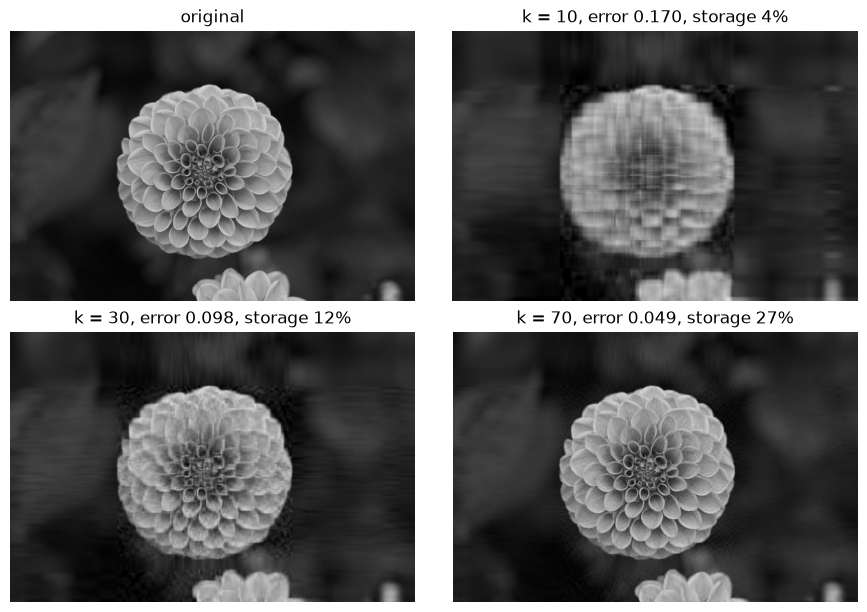

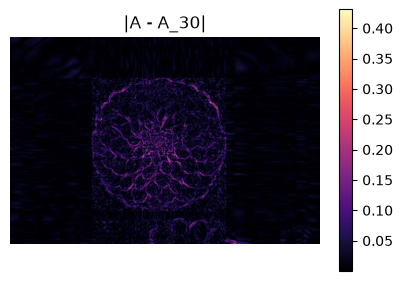

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(9, 6.2))
for a, k in zip(ax.flat, [None, 10, 30, 70]):
    X = img if k is None else rank_k(U, s, Vt, k)
    a.imshow(np.clip(X, 0, 1), cmap="gray", vmin=0, vmax=1); a.axis("off")
    a.set_title("original" if k is None else f"k = {k}, error {rel(X):.3f}, storage {storage(k, m, n):.0%}")
plt.tight_layout(); plt.show()
plt.figure(figsize=(5, 3.4)); plt.imshow(np.abs(img - rank_k(U, s, Vt, 30)), cmap="magma"); plt.axis("off")
plt.title("|A - A_30|"); plt.colorbar(); plt.show()

**Your answer.** The error at $k=30$ sits at the sharp edges and fine textures (petal borders, small details), because each layer $\sigma_j\mathbf u_j\mathbf v_j^\top$ is an outer product, i.e. a 'row pattern times column pattern' that can only build smooth, axis-aligned structures, so representing a thin diagonal edge needs many layers.

---
## A2. Denoising

Now we observe $Y = A + E$, where the entries of $E$ are independent $\mathcal N(0, \text{sd}^2)$. Two facts, stated without proof:

- **Weyl's inequality** for singular values: $|\sigma_j(A+E) - \sigma_j(A)| \le \|E\|_2$ for every $j$.
- **Noise floor.** For an $m\times n$ matrix with independent $\mathcal N(0,\text{sd}^2)$ entries and $m, n$ large, $\|E\|_2 \approx \text{sd}\,(\sqrt m + \sqrt n)$.

So singular values of $A$ well below the floor are drowned by the noise, and those well above it survive with a small shift. This suggests keeping only the singular values of $Y$ that stand above the floor.

In [9]:
sd = 0.05
E = sd * np.random.default_rng(4).standard_normal((m, n))
Y = img + E
print(f"sd = {sd}: error of the noisy image {rel(Y):.4f}")

sd = 0.05: error of the noisy image 0.1606


**(a)** *Predict, then compute.* Predict $\|E\|_2$ from the noise-floor formula. Then compute it, and check Weyl's inequality: compute $\max_j|\sigma_j(Y) - \sigma_j(A)|$ and compare it with $\|E\|_2$.

**Your prediction** *(write it before running the next cell)*: $\|E\|_2\approx 0.05(\sqrt{427}+\sqrt{640})\approx 2.30$, and by Weyl $\max_j|\sigma_j(Y)-\sigma_j(A)|$ will be at most that, probably noticeably smaller.

In [10]:
floor = sd * (np.sqrt(m) + np.sqrt(n))
normE = np.linalg.norm(E, 2)
UY, sY, VYt = np.linalg.svd(Y, full_matrices=False)
weyl = np.max(np.abs(sY - s))
print(f"predicted floor  sd(sqrt m + sqrt n) = {floor:.3f}")
print(f"actual ||E||_2                       = {normE:.3f}")
print(f"max_j |sigma_j(Y) - sigma_j(A)|      = {weyl:.3f}  <= ||E||_2: {weyl <= normE}")

predicted floor  sd(sqrt m + sqrt n) = 2.298
actual ||E||_2                       = 2.303
max_j |sigma_j(Y) - sigma_j(A)|      = 1.151  <= ||E||_2: True


**Your answer.** The floor formula gives 2.298 and the actual $\|E\|_2=2.303$ (almost perfect), and the largest singular-value shift is 1.151, which respects Weyl's bound $\le\|E\|_2$ with a factor-2 margin.

**(b)** Plot the singular values of $A$ and of $Y$ together with the floor. Then compare two choices of the rank for the truncated SVD of $Y$:
- the **threshold rule** $k_{\text{thr}} = \#\{j : \sigma_j(Y) > \text{floor}\}$;
- the **oracle** $k_{\text{or}}$, the rank that minimises the error against the clean image, found by trying $k = 1,\dots,200$.

Report both ranks and errors. Why can the oracle not be used in practice?

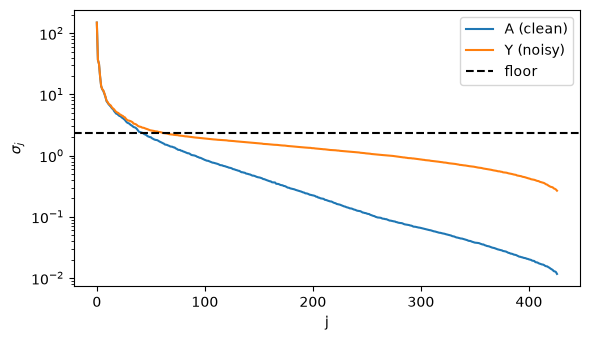

threshold rule: k = 65, error 0.1031
oracle:         k = 52, error 0.1009


In [11]:
plt.figure(figsize=(6, 3.5))
plt.semilogy(s, label="A (clean)"); plt.semilogy(sY, label="Y (noisy)")
plt.axhline(floor, color="k", ls="--", label="floor")
plt.xlabel("j"); plt.ylabel(r"$\sigma_j$"); plt.legend(); plt.tight_layout(); plt.show()

k_thr = int(np.sum(sY > floor))
errs_Y = [rel(rank_k(UY, sY, VYt, k)) for k in range(1, 201)]
k_or = int(np.argmin(errs_Y)) + 1
print(f"threshold rule: k = {k_thr}, error {rel(rank_k(UY, sY, VYt, k_thr)):.4f}")
print(f"oracle:         k = {k_or}, error {errs_Y[k_or - 1]:.4f}")

**Your answer.** The threshold rule gives $k_{thr}=65$ with error 0.1031, close to the oracle $k_{or}=52$ with error 0.1009, but the oracle cannot be used in practice because it needs the clean image to measure the error, and if we had it we would not need to denoise.

**(c)** Truncation keeps a layer completely or drops it completely. A softer choice multiplies layer $j$ by a **filter factor**
$$f_j = \frac{\sigma_j^2}{\sigma_j^2 + \lambda},$$
the same factors as in Tikhonov regularisation (frame `tikhonov-filter`). Implement `filter_factors(s, lam)` and `spectral_filter(U, s, Vt, f)`, which returns $\sum_j f_j\sigma_j\mathbf{u}_j\mathbf{v}_j^\top$. Use $\lambda = \text{floor}^2$: what is $f_j$ for a singular value exactly at the floor? Compare the error with (b).

In [12]:
def filter_factors(s, lam):
    return s ** 2 / (s ** 2 + lam)

def spectral_filter(U, s, Vt, f):
    return (U * (f * s)) @ Vt

In [13]:
# check
assert np.allclose(spectral_filter(U, s, Vt, np.ones_like(s)), img)
f = filter_factors(sY, floor ** 2)
print(f"soft filter, lambda = floor^2: error {rel(spectral_filter(UY, sY, VYt, f)):.4f}; "
      f"effective rank sum(f) = {f.sum():.1f}")

soft filter, lambda = floor^2: error 0.0933; effective rank sum(f) = 121.7


**Your answer.** At $\sigma_j=\text{floor}$ we get $f_j=\text{floor}^2/(2\,\text{floor}^2)=1/2$, and the soft filter gives error 0.0933, better than both hard truncations (0.1031 and 0.1009) because it shrinks borderline layers instead of keeping or killing them entirely.

**(d)** *Predict, then compute.* Double the noise, $\text{sd} = 0.1$ (same seed). Will the oracle rank go up or down, and roughly by how much? Then repeat (a)–(c) for $\text{sd} = 0.1$. Write a function `denoise_report(sd)` that prints the floor, $\|E\|_2$, the noisy error, both ranks with their errors, and the soft-filter error; run it for both noise levels.

**Your prediction** *(write it before running the next cell)*: The oracle rank goes down, since the floor doubles and more singular values sink below it, roughly to half (about 25–30).

In [14]:
def denoise_report(sd):
    E = sd * np.random.default_rng(4).standard_normal((m, n))
    Y = img + E
    floor = sd * (np.sqrt(m) + np.sqrt(n))
    UY, sY, VYt = np.linalg.svd(Y, full_matrices=False)
    k_thr = int(np.sum(sY > floor))
    errs = [rel(rank_k(UY, sY, VYt, k)) for k in range(1, 201)]
    k_or = int(np.argmin(errs)) + 1
    soft = rel(spectral_filter(UY, sY, VYt, filter_factors(sY, floor ** 2)))
    print(f"sd = {sd}: floor {floor:.2f}, ||E||_2 {np.linalg.norm(E, 2):.2f}, noisy error {rel(Y):.4f}")
    print(f"   threshold k = {k_thr} (error {rel(rank_k(UY, sY, VYt, k_thr)):.4f}), "
          f"oracle k = {k_or} (error {errs[k_or - 1]:.4f}), soft filter error {soft:.4f}")

for sd_ in [0.05, 0.1]:
    denoise_report(sd_)

sd = 0.05: floor 2.30, ||E||_2 2.30, noisy error 0.1606
   threshold k = 65 (error 0.1031), oracle k = 52 (error 0.1009), soft filter error 0.0933
sd = 0.1: floor 4.60, ||E||_2 4.61, noisy error 0.3212
   threshold k = 35 (error 0.1608), oracle k = 27 (error 0.1549), soft filter error 0.1568


**Your answer.** With sd = 0.1 the floor doubles to 4.60, the oracle rank drops from 52 to 27 and the threshold rank from 65 to 35, while the best error grows from about 0.10 to about 0.155 (the soft filter is now no better than the oracle truncation).

**(e)** At $\text{sd} = 0.05$ the best truncation reduces the error from about 16% to about 10%. Why is the gain so modest? Give two reasons, one about the spectrum you plotted in A1(a) and one about the noise that remains in the kept layers. (*Hint:* how many numbers does a rank-$k$ matrix have, and how much noise lands in each?)

**Your answer.** First, the spectrum decays slowly (A1(a)), so many useful layers are below the floor and are lost together with the noise; second, the kept rank-$k$ part has $k(m+n-k)\approx 52\cdot1015$ free parameters, so a fraction $\approx k(m+n)/(mn)\approx 20\%$ of the noise energy still lands in the kept layers and is not removed.

---
## A3. Deblurring

A camera that is slightly out of focus replaces each pixel by a weighted average of its neighbours. With **periodic** boundary conditions (the image wraps around at the edges) this is a 2-D **circular convolution** with a kernel $c$, here a Gaussian of width $w = 2$ pixels:
$$b = c \circledast x + e, \qquad e \sim \mathcal N(0, \eta^2 I).$$
As a matrix acting on the vectorised image, the blur $C$ is $mn \times mn$ and **block circulant with circulant blocks**. The convolution theorem says $\operatorname{fft2}(c \circledast x) = \operatorname{fft2}(c)\cdot\operatorname{fft2}(x)$ entrywise, so $C = F^{-1}\operatorname{diag}(\hat c)F$, where $F$ is the 2-D DFT and $\hat c = \operatorname{fft2}(c)$. Since $F/\sqrt{mn}$ is unitary, the singular values of $C$ are the numbers $|\hat c_j|$ and the singular vectors are Fourier modes. **The SVD of the blur costs one FFT.**

In [15]:
def kernel(m, n, w):
    # periodic Gaussian blur kernel centred at pixel (0, 0), entries sum to 1
    i = np.minimum(np.arange(m), m - np.arange(m))
    j = np.minimum(np.arange(n), n - np.arange(n))
    K = np.exp(-(i[:, None] ** 2 + j[None, :] ** 2) / (2 * w ** 2))
    return K / K.sum()

w = 2.0
kh = np.fft.fft2(kernel(m, n, w))                                 # the "singular values", with phases
blur = lambda X: np.real(np.fft.ifft2(np.fft.fft2(X) * kh))       # X -> C X, never forming C

**(a)** *The 1-D version, explicitly.* For a vector $c\in\mathbb R^N$ the circulant matrix has entries $C_{ij} = c_{(i-j) \bmod N}$, so that $C\mathbf x = c\circledast\mathbf x$. Implement `circulant(c)`, **check** it against `scipy.linalg.circulant`, and check that $C\mathbf x$ equals the FFT formula. Then confirm that the singular values of $C$ for the 64-point kernel below are the numbers $|\hat c_j|$, up to order.

In [16]:
def circulant(c):
    N = len(c)
    idx = (np.arange(N)[:, None] - np.arange(N)[None, :]) % N
    return c[idx]

In [17]:
# check
c1 = kernel(64, 1, w)[:, 0]
C1 = circulant(c1)
x1 = np.random.default_rng(0).standard_normal(64)
assert np.allclose(C1, sl.circulant(c1))
assert np.allclose(C1 @ x1, np.real(np.fft.ifft(np.fft.fft(c1) * np.fft.fft(x1))))
sv = np.sort(np.linalg.svd(C1, compute_uv=False))
print("singular values of C equal |fft(c)|:", np.allclose(sv, np.sort(np.abs(np.fft.fft(c1)))))
print("largest and smallest:", sv[-1], sv[0])

singular values of C equal |fft(c)|: True
largest and smallest: 0.9999999999999999 5.350575938628612e-09


**(b)** *Cost.* Compute the memory, in GB, needed to store $C$ for our image as a dense `float64` matrix, and the order of magnitude of the flop count of its SVD ($\approx (mn)^3$ up to a modest constant). Compare with the cost of one 2-D FFT, about $5\,mn\log_2(mn)$ flops. What is the largest image whose $C$ fits into 16 GB of memory?

In [18]:
N = m * n
mem_gb = N ** 2 * 8 / 1e9
svd_flops = N ** 3
fft_flops = 5 * N * np.log2(N)
N_max = np.sqrt(16e9 / 8)
print(f"N = mn = {N}")
print(f"dense C: {mem_gb:.0f} GB, SVD ~ {svd_flops:.1e} flops")
print(f"one fft2: ~ {fft_flops:.1e} flops  (ratio {svd_flops / fft_flops:.1e})")
print(f"largest image with C in 16 GB: {N_max:.0f} pixels, about {np.sqrt(N_max):.0f} x {np.sqrt(N_max):.0f}")

N = mn = 273280
dense C: 597 GB, SVD ~ 2.0e+16 flops
one fft2: ~ 2.5e+07 flops  (ratio 8.3e+08)
largest image with C in 16 GB: 44721 pixels, about 211 x 211


**Your answer.** Dense $C$ would need about 597 GB and its SVD about $2\cdot10^{16}$ flops, while one FFT costs about $2.5\cdot10^7$ flops (roughly $10^9$ times cheaper), and only an image of about 44,700 pixels (about $211\times211$) fits into 16 GB.

**(c)** *Predict, then compute.* The blurred image is observed with noise of size $\eta = 10^{-3}$ per pixel, a quarter of one grey level in an 8-bit image. Compute the condition number $\kappa(C) = \max|\hat c_j| / \min|\hat c_j|$. Then predict:
1. the size of the error of the **naive inverse** $x = C^{-1}b$ (divide by $\hat c$ in Fourier space);
2. the error of the naive inverse applied to the blurred image **without** noise.

Then compute both, together with the error of the blurred image itself.

**Your prediction** *(write it before running the next cell)*: Because $\kappa(C)$ is astronomically large, the naive inverse with noise will be complete garbage (error far above 1), and without noise it should in theory be exact but in floating point rounding errors of size $10^{-16}$ are also amplified, so it will also be bad.

In [19]:
eta = 1e-3
noise = np.random.default_rng(11).standard_normal((m, n))     # one fixed draw, scaled by eta below
B0 = blur(img)                                                  # noise-free blurred image
B = B0 + eta * noise
print(f"eta = {eta}: error of the blurred image {rel(B):.4f}")

eta = 0.001: error of the blurred image 0.1086


In [20]:
def deblur_naive(B, kh):
    return np.real(np.fft.ifft2(np.fft.fft2(B) / kh))

kappa = np.abs(kh).max() / np.abs(kh).min()
print(f"kappa(C) = {kappa:.2e}  (min |c_hat| = {np.abs(kh).min():.2e})")
print(f"blurred image error:        {rel(B):.4f}")
print(f"naive inverse with noise:   {rel(deblur_naive(B, kh)):.3e}")
print(f"naive inverse without noise:{rel(deblur_naive(B0, kh)):.3e}")

kappa(C) = 8.38e+18  (min |c_hat| = 1.19e-19)
blurred image error:        0.1086
naive inverse with noise:   3.726e+13
naive inverse without noise:8.544e+00


**Your answer.** $\kappa(C)\approx8.4\cdot10^{18}$, the naive inverse with noise has error $3.7\cdot10^{13}$ and even without noise 8.5 (versus 0.109 for the blurred image itself), because dividing by tiny $\hat c_j$ blows up both measurement noise and round-off.

**(d)** Implement two regularised inverses, both in Fourier space:
- `deblur_tikhonov(B, kh, lam)` with filter factors $f_j = |\hat c_j|^2/(|\hat c_j|^2+\lambda)$, that is $\hat x = \overline{\hat c}\,\hat b/(|\hat c|^2+\lambda)$;
- `deblur_tsvd(B, kh, tau)`, the truncated SVD: keep $\hat b_j/\hat c_j$ where $|\hat c_j| > \tau$ and set the rest to zero.

Sweep $\lambda$ and $\tau$ over the grids below and plot both errors on one axis against $\lambda$ and $\tau^2$. Report the best value of each (the oracle) and the fraction of frequencies the best truncation keeps. Explain from the filter factors why the best $\tau$ is close to $\sqrt\lambda$.

Tikhonov oracle: lambda = 5.6e-04, error 0.0667
TSVD oracle:     tau = 1.8e-02 (tau^2 = 3.2e-04), error 0.0697, keeps 16.0% of frequencies


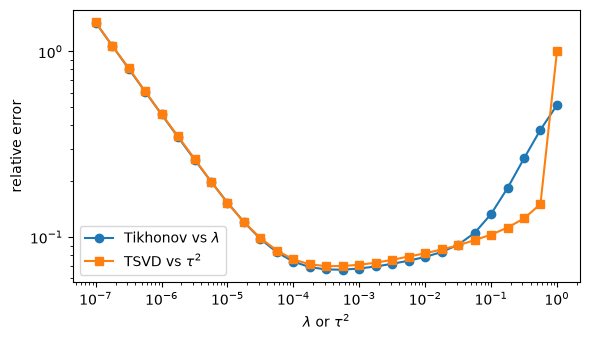

In [21]:
def deblur_tikhonov(B, kh, lam):
    Bh = np.fft.fft2(B)
    return np.real(np.fft.ifft2(np.conj(kh) * Bh / (np.abs(kh) ** 2 + lam)))

def deblur_tsvd(B, kh, tau):
    Bh = np.fft.fft2(B)
    keep = np.abs(kh) > tau
    Xh = np.zeros_like(Bh)
    Xh[keep] = Bh[keep] / kh[keep]
    return np.real(np.fft.ifft2(Xh))

lams = 10.0 ** np.arange(-7, 0.01, 0.25)
taus = np.sqrt(lams)
err_tik = np.array([rel(deblur_tikhonov(B, kh, l)) for l in lams])
err_tsvd = np.array([rel(deblur_tsvd(B, kh, t)) for t in taus])
lam_best, tau_best = lams[err_tik.argmin()], taus[err_tsvd.argmin()]
print(f"Tikhonov oracle: lambda = {lam_best:.1e}, error {err_tik.min():.4f}")
print(f"TSVD oracle:     tau = {tau_best:.1e} (tau^2 = {tau_best**2:.1e}), error {err_tsvd.min():.4f}, "
      f"keeps {np.mean(np.abs(kh) > tau_best):.1%} of frequencies")
plt.figure(figsize=(6, 3.5))
plt.loglog(lams, err_tik, "o-", label="Tikhonov vs $\\lambda$")
plt.loglog(taus ** 2, err_tsvd, "s-", label="TSVD vs $\\tau^2$")
plt.xlabel(r"$\lambda$ or $\tau^2$"); plt.ylabel("relative error"); plt.legend(); plt.tight_layout(); plt.show()

**Your answer.** The Tikhonov oracle is $\lambda=5.6\cdot10^{-4}$ with error 0.0667 and the TSVD oracle is $\tau=1.8\cdot10^{-2}$ ($\tau^2=3.2\cdot10^{-4}$) with error 0.0697, keeping 16% of the frequencies, and $\tau\approx\sqrt\lambda$ because the Tikhonov factor $f_j$ switches from about 1 to about 0 exactly where $|\hat c_j|^2\approx\lambda$, which is the cut TSVD makes at $|\hat c_j|=\tau$.

**(e)** *Choosing $\lambda$ without the truth.* The true image leaves the residual $\|Cx - b\| = \|e\| \approx \eta\sqrt{mn}$. The **discrepancy principle** asks the same of the reconstruction: choose the largest $\lambda$ on the grid with $\|Cx_\lambda - b\| \le \eta\sqrt{mn}$. Explain why it would be a bad idea to ask for a much smaller residual.

Implement `discrepancy_lambda(B, kh, eta, lams)`. Compute the residual in Fourier space: by Parseval, $\|r\| = \|\hat r\|/\sqrt{mn}$ with $\hat r = (1 - f)\,\hat b$. Then, for $\eta = 10^{-3}$ and $\eta = 10^{-2}$ (same `noise` draw), report the oracle $\lambda$ and the discrepancy $\lambda$ with their errors. How much do you lose by not knowing the true image?

In [22]:
def discrepancy_lambda(B, kh, eta, lams):
    Bh = np.fft.fft2(B)
    N = B.size
    target = eta * np.sqrt(N)
    for lam in sorted(lams, reverse=True):
        f = np.abs(kh) ** 2 / (np.abs(kh) ** 2 + lam)
        r = np.linalg.norm((1 - f) * Bh) / np.sqrt(N)
        if r <= target:
            return lam
    return min(lams)

print(" eta   | oracle lambda  error | discrepancy lambda  error")
for eta_ in [1e-3, 1e-2]:
    Be = B0 + eta_ * noise
    errs = np.array([rel(deblur_tikhonov(Be, kh, l)) for l in lams])
    lo = lams[errs.argmin()]
    ld = discrepancy_lambda(Be, kh, eta_, lams)
    print(f" {eta_:.0e} | {lo:12.1e} {errs.min():.4f} | {ld:17.1e} {rel(deblur_tikhonov(Be, kh, ld)):.4f}")

 eta   | oracle lambda  error | discrepancy lambda  error
 1e-03 |      5.6e-04 0.0667 |           5.6e-04 0.0667
 1e-02 |      1.8e-02 0.0894 |           1.0e-02 0.0900


**Your answer.** Demanding a much smaller residual than the noise would mean fitting the noise itself (overfitting), and in our test the discrepancy principle matches the oracle exactly at $\eta=10^{-3}$ (error 0.0667) and loses only 0.0006 at $\eta=10^{-2}$ (0.0900 vs 0.0894), so not knowing the true image costs almost nothing.

**(f)** Show a crop of the true image, the blurred noisy image, the naive inverse, and the discrepancy-principle reconstruction, for $\eta = 10^{-3}$. Which details come back, and which do not? Relate what you see to the frequencies that the filter removes.

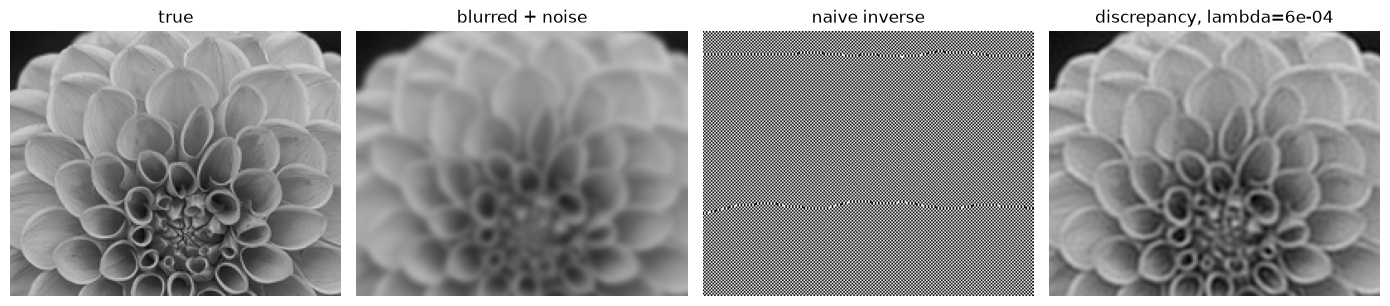

In [23]:
lam_d = discrepancy_lambda(B, kh, eta, lams)
crop = (slice(100, 260), slice(200, 400))
pics = [img, B, deblur_naive(B, kh), deblur_tikhonov(B, kh, lam_d)]
titles = ["true", "blurred + noise", "naive inverse", f"discrepancy, lambda={lam_d:.0e}"]
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
for a, X, t in zip(ax, pics, titles):
    a.imshow(np.clip(X[crop], 0, 1), cmap="gray", vmin=0, vmax=1); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

**Your answer.** The discrepancy reconstruction brings back mid-scale details such as petal edges and contours, but the finest textures stay lost because their high frequencies have $|\hat c_j|\ll\sqrt\lambda$ and are filtered out ($f_j\approx0$), while the naive inverse is pure noise.

---
# Extension — attempt **at most one** in the whole lab

End your extension with a paragraph headed **Finding**: one claim you can defend at the defence, supported by a number in this notebook.

## E1. Choosing λ when the noise level is unknown

*This topic was not lectured; the introduction below is all you need.*

The discrepancy principle needs $\eta$. **Generalised cross-validation** (GCV) does not. Write the Tikhonov reconstruction as $x_\lambda = C(\lambda)b$ and the fitted data as $Cx_\lambda = H_\lambda b$ with the *influence matrix* $H_\lambda = C(C^\top C + \lambda I)^{-1}C^\top$. GCV chooses the $\lambda$ that minimises
$$G(\lambda) = \frac{\frac1N\|(I - H_\lambda)b\|^2}{\left(\frac1N\operatorname{trace}(I - H_\lambda)\right)^2}, \qquad N = mn.$$
It approximates leave-one-out cross-validation: how well does the model predict a pixel it was not fitted to? The denominator penalises small $\lambda$, where $H_\lambda \approx I$ and the fit simply reproduces the noise.

**(a)** *Show* that the eigenvalues of $H_\lambda$ are the filter factors $f_j = |\hat c_j|^2/(|\hat c_j|^2+\lambda)$, so that $\operatorname{trace}(I - H_\lambda) = N - \sum_j f_j$, and that $\|(I-H_\lambda)b\| = \|(1-f)\hat b\|/\sqrt N$. Interpret $\sum_j f_j$ as an "effective number of parameters".

**Your answer.** Not attempted.

**(b)** Implement `gcv(B, kh, lam)` and choose $\lambda$ by minimising it over `lams`, for $\eta = 10^{-3}$ and $10^{-2}$. Compare the GCV choice with the oracle and with the discrepancy principle, and plot $G(\lambda)$ together with the error curve. Then estimate the noise level from the GCV fit, $\hat\eta^2 = \|(I - H_\lambda)b\|^2/\operatorname{trace}(I-H_\lambda)$, and compare it with the true $\eta$.

In [24]:
def gcv(B, kh, lam):
    # YOUR CODE HERE
    raise NotImplementedError

# YOUR CODE HERE

**Your answer.** Not attempted.

---
**Before you submit:** run `Kernel → Restart & Run All`, check that every written answer is filled in, and make sure your extension (if any) ends with a **Finding**.